In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from joblib import dump
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor


In [2]:
df = pd.read_csv("taxis.csv")
df.head(10)

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,23-03-2019 20:21,23-03-2019 20:27,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,04-03-2019 16:11,04-03-2019 16:19,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,27-03-2019 17:53,27-03-2019 18:00,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,10-03-2019 01:23,10-03-2019 01:49,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,30-03-2019 13:27,30-03-2019 13:37,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
5,11-03-2019 10:37,11-03-2019 10:47,1,0.49,7.5,2.16,0.0,12.96,yellow,credit card,Times Sq/Theatre District,Midtown East,Manhattan,Manhattan
6,26-03-2019 21:07,26-03-2019 21:17,1,3.65,13.0,2.00,0.0,18.80,yellow,credit card,Battery Park City,Two Bridges/Seward Park,Manhattan,Manhattan
7,22-03-2019 12:47,22-03-2019 12:58,0,1.40,8.5,0.00,0.0,11.80,yellow,NaN,Murray Hill,Flatiron,Manhattan,Manhattan
8,23-03-2019 11:48,23-03-2019 12:06,1,3.63,15.0,1.00,0.0,19.30,yellow,credit card,East Harlem South,Midtown Center,Manhattan,Manhattan
9,08-03-2019 16:18,08-03-2019 16:26,1,1.52,8.0,1.00,0.0,13.30,yellow,credit card,Lincoln Square East,Central Park,Manhattan,Manhattan


In [3]:
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')

In [4]:
df.shape

(6433, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup           6433 non-null   object 
 1   dropoff          6433 non-null   object 
 2   passengers       6433 non-null   int64  
 3   distance         6433 non-null   float64
 4   fare             6433 non-null   float64
 5   tip              6433 non-null   float64
 6   tolls            6433 non-null   float64
 7   total            6433 non-null   float64
 8   color            6433 non-null   object 
 9   payment          6389 non-null   object 
 10  pickup_zone      6407 non-null   object 
 11  dropoff_zone     6388 non-null   object 
 12  pickup_borough   6407 non-null   object 
 13  dropoff_borough  6388 non-null   object 
dtypes: float64(5), int64(1), object(8)
memory usage: 703.7+ KB


In [6]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [7]:
df["color"].unique()

array(['yellow', 'green'], dtype=object)

In [8]:
df["pickup_zone"].fillna(df["pickup_zone"].mode())

0             Lenox Hill West
1       Upper West Side South
2               Alphabet City
3                   Hudson Sq
4                Midtown East
                ...          
6428        East Harlem North
6429                  Jamaica
6430      Crown Heights North
6431            East New York
6432              Boerum Hill
Name: pickup_zone, Length: 6433, dtype: object

In [9]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

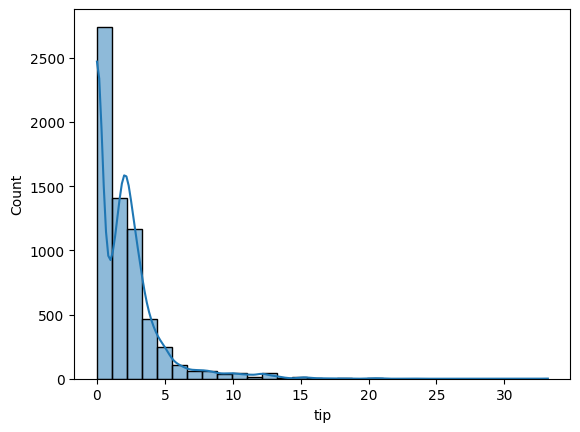

In [10]:
sns.histplot(df,x="tip",bins=30,kde=True)
plt.show()

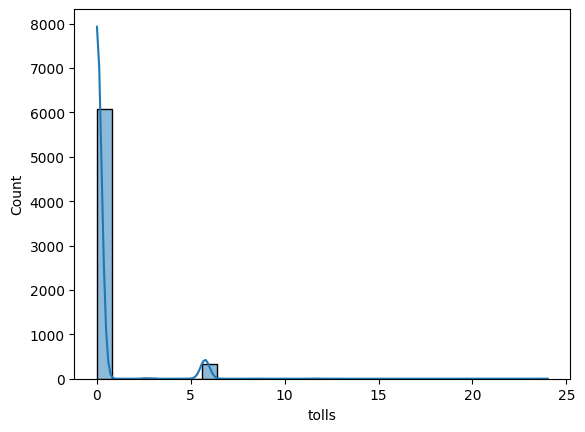

In [11]:
sns.histplot(df,x="tolls",bins=30,kde=True)
plt.show()

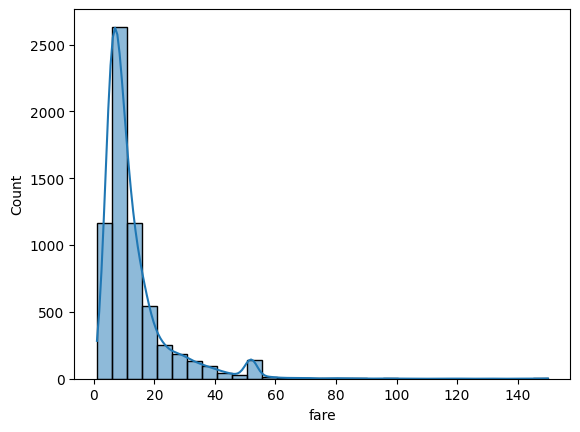

In [12]:
sns.histplot(df,x="fare",bins=30,kde=True)
plt.show()

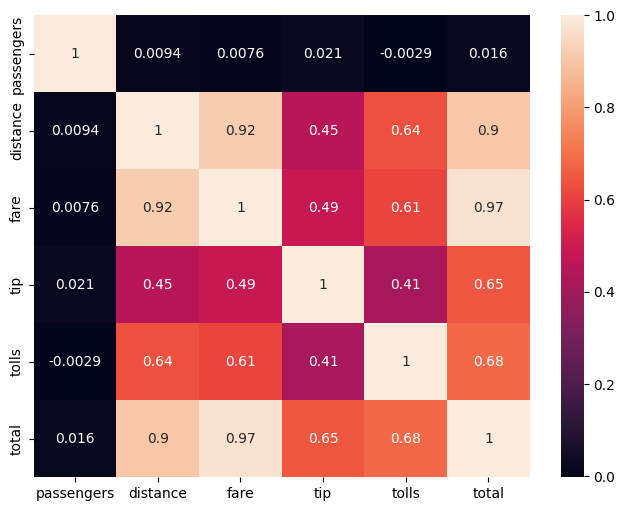

In [13]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

In [14]:
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')

In [15]:
df["pickup_zone"].unique()

array(['Lenox Hill West', 'Upper West Side South', 'Alphabet City',
       'Hudson Sq', 'Midtown East', 'Times Sq/Theatre District',
       'Battery Park City', 'Murray Hill', 'East Harlem South',
       'Lincoln Square East', 'LaGuardia Airport', 'Lincoln Square West',
       'Financial District North', 'Upper West Side North',
       'East Chelsea', 'Midtown Center', 'Gramercy',
       'Penn Station/Madison Sq West', 'Sutton Place/Turtle Bay North',
       'West Chelsea/Hudson Yards', 'Clinton East', 'Clinton West',
       'UN/Turtle Bay South', 'Midtown South', 'Midtown North',
       'Garment District', 'Lenox Hill East', 'Flatiron',
       'TriBeCa/Civic Center', nan, 'Upper East Side North',
       'West Village', 'Greenwich Village South', 'JFK Airport',
       'East Village', 'Union Sq', 'Yorkville West', 'Central Park',
       'Meatpacking/West Village West', 'Kips Bay', 'Morningside Heights',
       'Astoria', 'East Tremont', 'Upper East Side South',
       'Financial Distric

In [16]:
col = ['passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color']
df_final = df[col]
df_final.head()

,passengers,distance,fare,tip,tolls,total,color
0,1,1.60,7.0,2.15,0.0,12.95,yellow
1,1,0.79,5.0,0.00,0.0,9.30,yellow
2,1,1.37,7.5,2.36,0.0,14.16,yellow
3,1,7.70,27.0,6.15,0.0,36.95,yellow
4,3,2.16,9.0,1.10,0.0,13.40,yellow


In [17]:
lab_encod = LabelEncoder()
df_final["color"] = lab_encod.fit_transform(df_final["color"])
df_final.head()

C:\Users\Amir sohail\AppData\Local\Temp\ipykernel_10388\2332296055.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final["color"] = lab_encod.fit_transform(df_final["color"])


,passengers,distance,fare,tip,tolls,total,color
0,1,1.60,7.0,2.15,0.0,12.95,1
1,1,0.79,5.0,0.00,0.0,9.30,1
2,1,1.37,7.5,2.36,0.0,14.16,1
3,1,7.70,27.0,6.15,0.0,36.95,1
4,3,2.16,9.0,1.10,0.0,13.40,1


In [18]:
col = ['passengers', 'distance', 'fare', 'tip', 'tolls']
scaler = StandardScaler()
df_final[col] = scaler.fit_transform(df_final[col])
df_final.head()

C:\Users\Amir sohail\AppData\Local\Temp\ipykernel_10388\3379331860.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final[col] = scaler.fit_transform(df_final[col])


,passengers,distance,fare,tip,tolls,total,color
0,-0.448004,-0.372199,-0.527324,0.069753,-0.229849,12.95,1
1,-0.448004,-0.583821,-0.700471,-0.808383,-0.229849,9.30,1
2,-0.448004,-0.432289,-0.484038,0.155524,-0.229849,14.16,1
3,-0.448004,1.221502,1.204142,1.703493,-0.229849,36.95,1
4,1.213575,-0.225892,-0.354178,-0.359104,-0.229849,13.40,1


In [19]:
X = df_final.drop(["total"],axis=1)
y = df_final["total"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [20]:
models = {
    "LR":LinearRegression(),
    "KNN":KNeighborsRegressor(n_neighbors=5,weights="distance"),
    "XG":XGBRegressor(),
    "GB":GradientBoostingRegressor()
}

for i , model in models.items():
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    n = X_test.shape[0] 
    p = X_test.shape[1]
    r2 = r2_score(y_test,y_pred)
    r2_Ad = 1-((1-r2)*(n-1))/(n-p-1)  
    print(r2_Ad)

0.9963994566684973
0.9723133885830869


0.9888981214983178
0.9943843723289785


In [21]:
model_final = models["KNN"]
model_final.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [22]:
y_pred = model_final.predict(X_test)
n = X_test.shape[0] 
p = X_test.shape[1]
r2 = r2_score(y_test,y_pred)
r2_Ad = 1-((1-r2)*(n-1))/(n-p-1)  
print(r2_Ad)
print(mean_squared_error(y_test,y_pred))

0.9723133885830869
5.130417883572653


In [23]:
# dump(model_final,"KNN_model.pkl")
# dump(scaler,"scaler.pkl")
# dump(X.columns.tolist(),"columns.pkl")